In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load data
df = pd.read_excel("/content/cancer_lifetime_data.xlsx")

In [5]:
df.head()

,PatientID,CancerStage,Age,BMI,SmokingStatus,BloodPressure,Cholesterol,ExerciseHoursPerWeek,FamilyHistory,ExpectedLifetime
0,1,2,77,22.9,0,179,187,2.1,0,9.4
1,2,4,31,22.3,0,152,263,1.6,1,8.9
2,3,3,35,23.3,0,169,232,0.2,0,10.9
3,4,2,57,29.1,0,167,205,0.7,0,11.4
4,5,1,58,27.2,0,158,252,3.8,0,14.6


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   PatientID             1500 non-null   int64  
 1   CancerStage           1500 non-null   int64  
 2   Age                   1500 non-null   int64  
 3   BMI                   1500 non-null   float64
 4   SmokingStatus         1500 non-null   int64  
 5   BloodPressure         1500 non-null   int64  
 6   Cholesterol           1500 non-null   int64  
 7   ExerciseHoursPerWeek  1500 non-null   float64
 8   FamilyHistory         1500 non-null   int64  
 9   ExpectedLifetime      1500 non-null   float64
dtypes: float64(3), int64(7)
memory usage: 117.3 KB


In [7]:
import pandas as pd
df = pd.read_excel("/content/cancer_lifetime_data.xlsx")
# Drop PatientID and separate features and target
X = df.drop(['PatientID', 'ExpectedLifetime'], axis=1)
y = df['ExpectedLifetime']

In [8]:
df.describe()

,PatientID,CancerStage,Age,BMI,SmokingStatus,BloodPressure,Cholesterol,ExerciseHoursPerWeek,FamilyHistory,ExpectedLifetime
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,750.500000,2.305333,55.054667,25.140200,0.387333,144.734667,224.310667,2.496600,0.286667,11.140267
std,433.157015,1.117559,14.621293,4.040909,0.487303,20.414883,43.153427,1.433278,0.452355,2.930387
min,1.000000,1.000000,30.000000,12.000000,0.000000,110.000000,150.000000,0.000000,0.000000,2.900000
25%,375.750000,1.000000,43.000000,22.400000,0.000000,127.000000,187.000000,1.300000,0.000000,8.900000
50%,750.500000,2.000000,55.000000,25.300000,0.000000,143.000000,223.000000,2.500000,0.000000,11.300000
75%,1125.250000,3.000000,68.000000,27.800000,1.000000,163.000000,263.000000,3.725000,1.000000,13.400000
max,1500.000000,4.000000,80.000000,38.000000,1.000000,180.000000,300.000000,5.000000,1.000000,19.000000


In [9]:
df.shape

(1500, 10)

In [10]:
df.columns

Index(['PatientID', 'CancerStage', 'Age', 'BMI', 'SmokingStatus',
       'BloodPressure', 'Cholesterol', 'ExerciseHoursPerWeek', 'FamilyHistory',
       'ExpectedLifetime'],
      dtype='object')

In [11]:
df.isnull().sum()

,0
PatientID,0
CancerStage,0
Age,0
BMI,0
SmokingStatus,0
BloodPressure,0
Cholesterol,0
ExerciseHoursPerWeek,0
FamilyHistory,0
ExpectedLifetime,0


In [12]:
cat=df.select_dtypes(exclude=['number']).columns
num=df.select_dtypes(include=['number']).columns

In [13]:
cat

Index([], dtype='object')

In [14]:
num

Index(['PatientID', 'CancerStage', 'Age', 'BMI', 'SmokingStatus',
       'BloodPressure', 'Cholesterol', 'ExerciseHoursPerWeek', 'FamilyHistory',
       'ExpectedLifetime'],
      dtype='object')

In [15]:
# Feature types
numeric_feats = ['Age', 'BMI', 'BloodPressure', 'Cholesterol', 'ExerciseHoursPerWeek']
categorical_feats = ['CancerStage', 'SmokingStatus', 'FamilyHistory']

In [16]:
# Preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_feats),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_feats)
])

In [17]:
preprocessor

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['Age', 'BMI', 'BloodPressure', 'Cholesterol',
                                  'ExerciseHoursPerWeek']),
                                ('cat',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['CancerStage', 'SmokingStatus',
                                  'FamilyHistory'])])

In [18]:
# Full pipeline
pipeline = Pipeline([
    ('prep', preprocessor),
    ('reg', LinearRegression())
])

In [19]:
pipeline

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'BMI',
                                                   'BloodPressure',
                                                   'Cholesterol',
                                                   'ExerciseHoursPerWeek']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['CancerStage',
                                                   'SmokingStatus',
                                                   'FamilyHistory'])])),
                ('reg', LinearRegression())])

In [24]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
pipeline.fit(X_train, y_train)

# Predict
y_pred = pipeline.predict(X_test)

In [25]:
y_pred

array([14.12581162, 13.6344008 , 14.75046637, 11.85037548, 10.31741712,
        9.08288699, 12.62914658, 10.57221247,  9.62053008, 15.59863139,
       11.91733954, 11.65796823,  9.07965275,  8.32787834,  9.90207666,
        8.36131658, 10.35019096, 11.7191316 , 12.0358469 , 11.71624184,
       10.56871299, 12.34074574, 13.28442015,  9.05293464,  6.94269658,
        9.23583678,  5.20076359, 13.42836922, 12.80157853,  8.13605541,
       10.59555249, 14.46024563, 10.84824048,  9.14097929, 11.8162373 ,
       12.79365869, 11.80788361, 13.27462422, 13.98436512,  8.09152694,
       12.69871212, 15.12747323, 11.11895365, 14.64104527, 10.84511161,
       13.90055878, 13.71721924, 16.06722013, 10.321     ,  6.23485024,
       10.93367006,  9.13231028, 10.5363327 , 11.56097029,  9.17383734,
        7.6927827 , 13.2536576 , 10.17298345,  8.95881342, 10.13258896,
       11.05607214, 10.0027818 , 14.46468627,  7.11085349,  6.06209537,
       13.18042208, 12.16074414, 14.61928265, 15.40543591, 13.41

In [23]:


# Evaluation
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
r2_percentage = r2 * 100
cv_r2 = cross_val_score(pipeline, X, y, cv=5, scoring='r2').mean()

print(f"Total samples: {len(df)}")
print(f"Train samples: {len(y_train)}")
print(f"Test samples: {len(y_test)}\n")

Total samples: 1500
Train samples: 1200
Test samples: 300



In [26]:
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.2f}")
print(f"Model Accuracy (R² %): {r2_percentage:.2f}%")
print(f"Cross-validated R²: {cv_r2:.2f}")

RMSE: 1.02
R² Score: 0.88
Model Accuracy (R² %): 87.82%
Cross-validated R²: 0.88


In [27]:
# Test set results
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Residual': y_test.values - y_pred
})
print("\nTest Set Results:\n", results.head())


Test Set Results:
    Actual  Predicted  Residual
0    12.9  14.125812 -1.225812
1    14.1  13.634401  0.465599
2    14.5  14.750466 -0.250466
3    12.7  11.850375  0.849625
4    10.6  10.317417  0.282583


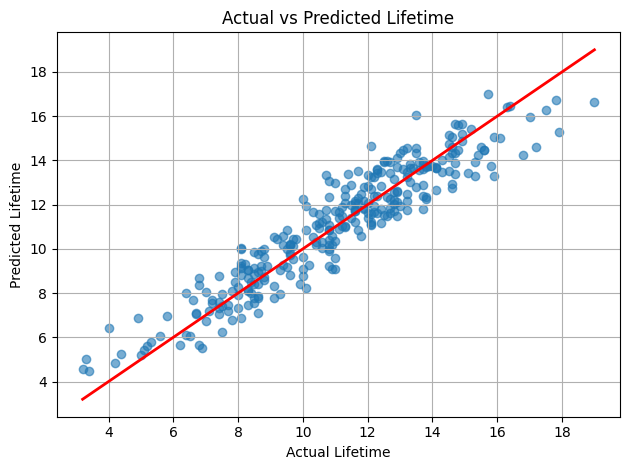

In [28]:
# Plot 1: Actual vs Predicted
plt.figure()
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2)
plt.xlabel("Actual Lifetime")
plt.ylabel("Predicted Lifetime")
plt.title("Actual vs Predicted Lifetime")
plt.grid(True)
plt.tight_layout()
plt.show()

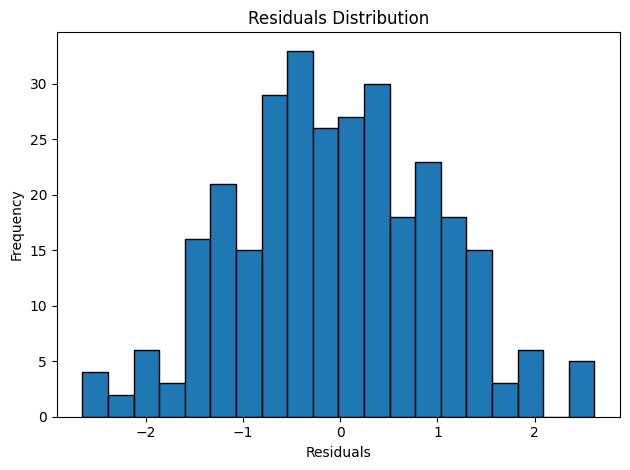

In [32]:
from weakref import KeyedRef
# Plot 2: Residuals histogram
plt.figure()
plt.hist(results['Residual'], bins=20, edgecolor='black')

plt.title("Residuals Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

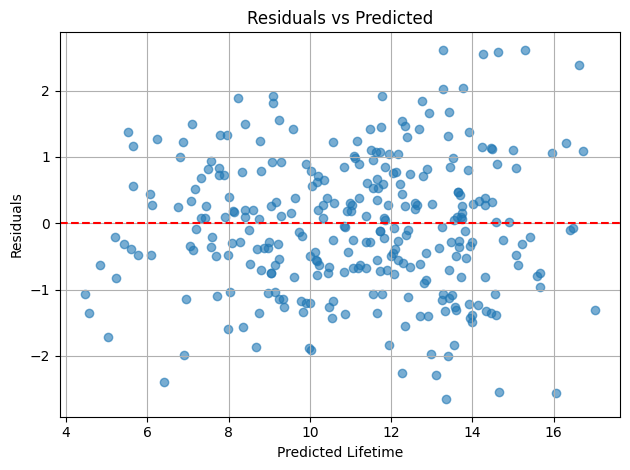

In [33]:
# Plot 3: Residuals vs Predicted
plt.figure()
plt.scatter(y_pred, results['Residual'], alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Lifetime")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.grid(True)
plt.tight_layout()
plt.show()

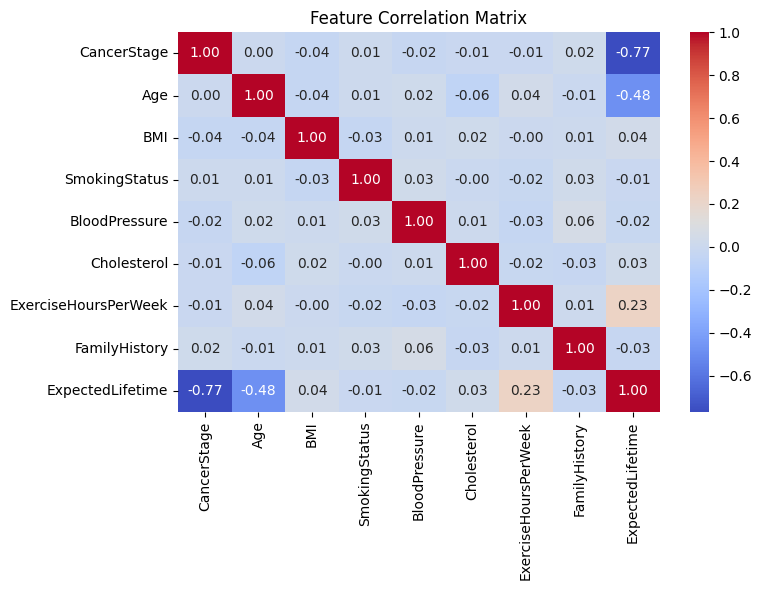

In [34]:
# Plot 4: Correlation heatmap (only numerical)
corr = df.drop('PatientID', axis=1).corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

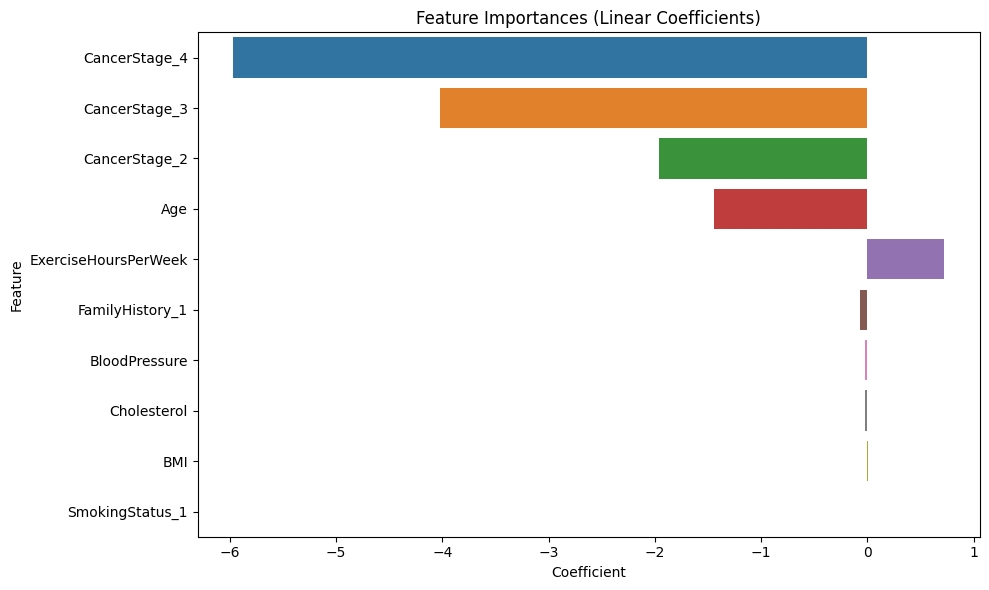

In [35]:
# Plot 5: Feature graph
onehot = pipeline.named_steps['prep'].named_transformers_['cat']
encoded_cat_feats = onehot.get_feature_names_out(categorical_feats)
all_feats = numeric_feats + list(encoded_cat_feats)

coeffs = pipeline.named_steps['reg'].coef_
coef_df = pd.DataFrame({'Feature': all_feats, 'Coefficient': coeffs})
coef_df = coef_df.sort_values(by='Coefficient', key=abs, ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient', y='Feature', data=coef_df, hue='Feature', dodge=False)
plt.title("Feature Importances (Linear Coefficients)")
plt.tight_layout()
plt.show()